# Домашнє завдання: Побудова класифікатора сентименту на основі набору даних Tweet Sentiment Extraction

**Мета:** Провести аналіз набору даних, виконати векторизацію текстових даних за допомогою методів bag-of-words та TF-IDF, порівняти їх, побудувати класифікатор та провести аналіз помилок.

**Набір даних:**
Дані беремо з цього змагання на Kaggle: https://www.kaggle.com/competitions/tweet-sentiment-extraction/data?select=train.csv


Якщо не вдається завантажиит з Kaggle, ось тут можна - https://drive.google.com/file/d/1kfu5zCRsDHxoBZigBlGIcCieKlws02HT/view?usp=sharing

Оригінальне змагання має дещо іншу задачу, але ми будемо поки будувати саме класифікатор.

Увага! В цьому наборі завдань для простоти експериментів ми будемо спочатку робити векторизацію на всьому наборі даних, а потім розбивку на train i test. В робочих проєктах ми теж можемо використати цей підхід для швидшої побудови PoC (proof of concept). Але фінальне рішення, яке ми будемо деплоїти - треба проводити за правилом - спочатку розбивка на трейн і тест, потім пишемо обробку для трейну, навчаємо векторизатори. І потім використовуємо готові векторизатори для тесту і всіх даних на етапі передбачення (інференсу).

### Завдання 1. Завантаження та ознайомлення з набором даних

- Завантажте набір даних `train.csv` з посилання та ознайомтеся з його структурою.
- Виведіть перші 5 рядків та основну статистику: кількість записів, типи колонок, кількість пропущених значень.
- Видаліть записи, в яких є пропущені значення.



In [3]:
import os
import numpy as np
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

data_dir = '/content/drive/MyDrive/ML1/data/'
print(os.listdir(data_dir))

Mounted at /content/drive
['credit', 'cars.csv', 'medical-charges.csv', 'workdata', 'kaggle_data', 'estimation_of_obesity_levels_based_on_eating_habits_and_physical.csv', 'regression_data.csv', 'customer_segmentation_train.csv', 'bank-additional-full.csv', 'bank_additional_full.xlsx', 'marketing_campaign.csv', 'tweet_sentiment_train.csv.zip']


In [4]:
file_name = 'tweet_sentiment_train.csv.zip'
raw_df = pd.read_csv(data_dir + file_name)

print(raw_df.shape)
display(raw_df.head())
raw_df.info()
print('\nпропуски по колонках:')
print(raw_df.isna().sum())

(27481, 4)


,textID,text,selected_text,sentiment
0,cb774db0d1,"I`d have responded, if I were going","I`d have responded, if I were going",neutral
1,549e992a42,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD,negative
2,088c60f138,my boss is bullying me...,bullying me,negative
3,9642c003ef,what interview! leave me alone,leave me alone,negative
4,358bd9e861,"Sons of ****, why couldn`t they put them on t...","Sons of ****,",negative


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27481 entries, 0 to 27480
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   textID         27481 non-null  object
 1   text           27480 non-null  object
 2   selected_text  27480 non-null  object
 3   sentiment      27481 non-null  object
dtypes: object(4)
memory usage: 858.9+ KB

пропуски по колонках:
textID           0
text             1
selected_text    1
sentiment        0
dtype: int64


In [5]:
df = raw_df.dropna().reset_index(drop=True)
print('було', raw_df.shape[0], 'стало', df.shape[0], 'видалено', raw_df.shape[0] - df.shape[0])

було 27481 стало 27480 видалено 1


### Завдання 2. Exploratory Data Analysis

- Проведіть аналіз кількості класів та розподілу міток. Класи знаходяться в колонці `sentiment`.
- Візуалізуйте розподіл довжин текстів в символах та зробіть висновок про довжини постів: якої довжини постів найбільше, що бачите з розподілу?



sentiment
neutral     11117
positive     8582
negative     7781
Name: count, dtype: int64
sentiment
neutral     40.45
positive    31.23
negative    28.32
Name: count, dtype: float64
базовий рівень, якщо завжди казати найчастіший клас: 0.4045


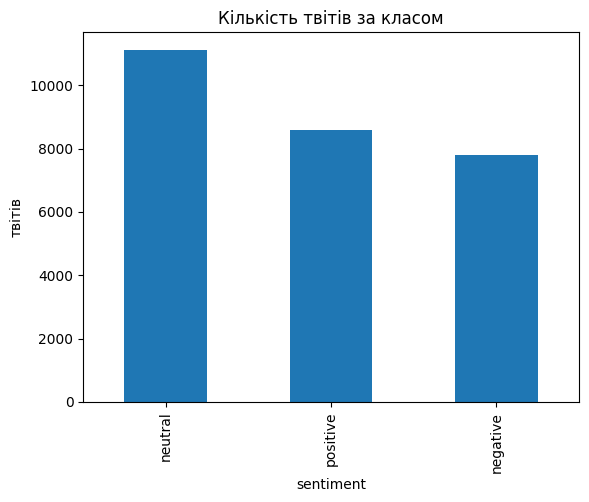

In [6]:
import matplotlib.pyplot as plt

counts = df.sentiment.value_counts()
print(counts)
print((counts / len(df) * 100).round(2))
print('базовий рівень, якщо завжди казати найчастіший клас: %.4f' % (counts.max() / len(df)))

counts.plot(kind='bar', title='Кількість твітів за класом')
plt.ylabel('твітів')
plt.show()

In [7]:
df['text_len'] = df.text.str.len()

print(df.text_len.describe().round(2))
print('\nмедіана:', df.text_len.median())
print('максимум:', df.text_len.max())
print('мінімум:', df.text_len.min())
print('довших за 140 символів:', (df.text_len > 140).sum())

count    27480.00
mean        68.33
std         35.60
min          3.00
25%         39.00
50%         64.00
75%         97.00
max        141.00
Name: text_len, dtype: float64

медіана: 64.0
максимум: 141
мінімум: 3
довших за 140 символів: 2


In [8]:
print('--- 3 найдовші ---')
for t in df.nlargest(3, 'text_len').text:
    print(len(t), repr(t))

print('\n--- 3 найкоротші ---')
for t in df.nsmallest(3, 'text_len').text:
    print(len(t), repr(t))

--- 3 найдовші ---
141 'Is so freaking bored on the bus. Hate being poor, ï¿½4.80 return for a 10 min train or ï¿½2 return for an HOUR long bus.ipod has no battery 2'
141 'just saw an advert for ATTICS TO EDEN on tv  out today and only ï¿½9.99 from HMV...so I`m not sure why I had to pay ï¿½13 at HMV...never mind'
140 'Feeling madly sorry for myself... - ï¿½Iï¿½M SECK D= Make me feel better  I should be going to a fashion show... http://tumblr.com/xz31werch'

--- 3 найкоротші ---
3 ' no'
3 ' aw'
3 ' ow'


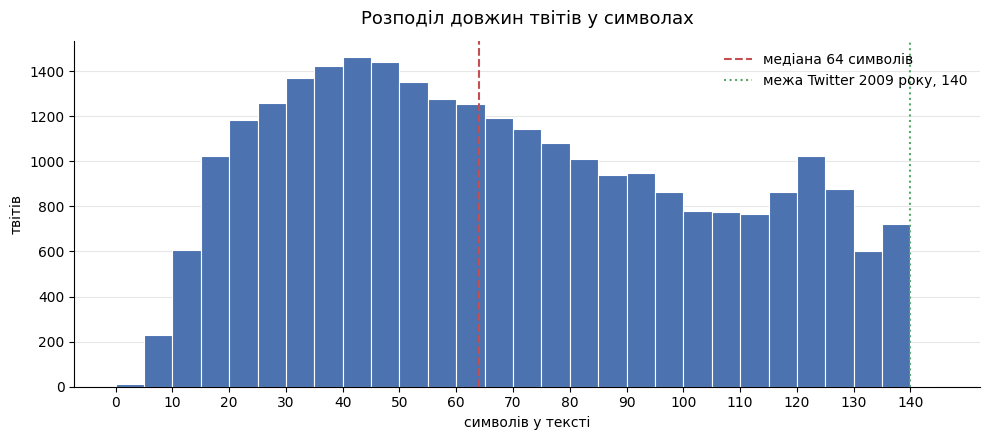

In [10]:
import numpy as np

bins = np.arange(0, 146, 5)                       # кошики по 5 символів, межі цілі
median_len = df.text_len.median()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(df.text_len, bins=bins, color='#4C72B0', edgecolor='white', linewidth=0.8)

ax.axvline(median_len, color='#C44E52', linestyle='--', linewidth=1.5,
           label='медіана %d символів' % median_len)
ax.axvline(140, color='#55A868', linestyle=':', linewidth=1.5,
           label='межа Twitter 2009 року, 140')

ax.set_title('Розподіл довжин твітів у символах', fontsize=13, pad=12)
ax.set_xlabel('символів у тексті')
ax.set_ylabel('твітів')
ax.set_xticks(np.arange(0, 146, 10))
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

           mean  median   std
sentiment                    
negative   70.5    66.0  35.2
neutral    65.2    59.0  36.4
positive   70.4    67.0  34.6


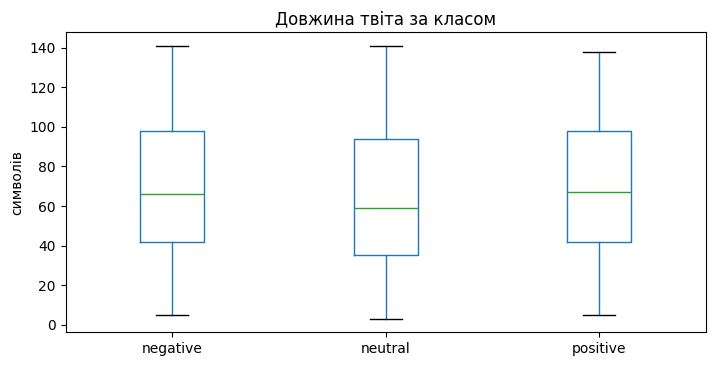

In [11]:
print(df.groupby('sentiment').text_len.agg(['mean', 'median', 'std']).round(1))

df.boxplot(column='text_len', by='sentiment', figsize=(8, 4), grid=False)
plt.suptitle('')
plt.title('Довжина твіта за класом')
plt.xlabel('')
plt.ylabel('символів')
plt.show()

**Висновок.**

Класи незбалансовані помірно: neutral 11 117 (40.45 %), positive 8 582
(31.23 %), negative 7 781 (28.32 %). Модель, яка завжди каже neutral, дає accuracy 0.4045, і це мій базовий рівень.

Довжини: медіана 64 символи, середня 68.3, квартилі 39 і 97, мінімум 3, максимум 141.
Розподіл не має одного піка. Маса розтягнута від 10 до 140 символів, найбільше твітів на 20 до 60 символах, далі спад, і окремий підйом на 115 до 140. Підйом під самою межею це твіти, дописані до упору: у 2009 році Twitter дозволяв 140 символів. Довших за 140 рівно 2 твіти, обидва на 141 символ, тож дані цілі.

Для моделі це означає, що документи дуже короткі. У середньому твіті близько 12 слів, і після видалення стоп-слів лишиться менше. Тому кожне слово важить багато, а векторизація дасть дуже розріджену матрицю.

### Завдання 3. Попередня обробка текстових даних та векторизація з bag of words


Наша задача тут отримати вектори методом bag of words колонки `text`, виконавши попередню обробку тексту.
Попередня обробка має включати
- видалення stopwords необхідної мови
- токенізація (розбиття текстів на фрагменти по 1 слову)
- стеммінг слів зі `SnowballStemmer`.
- самостійно задайте кількість слів в словнику для `sklearn.feature_extraction.text.CountVectorizer`. Можливо для цього доведеться виконати додатковий аналіз.

Ви також можете додати сюди додаткові методи очистки текстів, наприклад, видалення деяких символів чи груп символів, якщо в процесі роботи побачите, що хочете щось видалити.

Напишіть код аби виконати це завдання. Перед цим рекомендую детально ознайомитись з тим, що робить обʼєкт `sklearn.feature_extraction.text.CountVectorizer` за замовченням.

Це завдання можна виконати двома способами - один - максимально подібно до того, як ми це робили в лекції, другий - дещо інакше перегрупувавши етапи обробки тексту.




In [13]:
import re
import html
import nltk
from nltk.corpus import stopwords
from nltk.stem.snowball import SnowballStemmer

nltk.download('stopwords', quiet=True)

negations = {'no', 'not', 'nor', 'don', "don't", 'ain', 'aren', "aren't",
             'isn', "isn't", 'wasn', "wasn't", 'weren', "weren't",
             'didn', "didn't", 'doesn', "doesn't", 'won', "won't",
             'can', 'couldn', "couldn't", 'shouldn', "shouldn't"}

stop_words = set(stopwords.words('english')) - negations
print('стоп-слів у NLTK:', len(stopwords.words('english')),
      ' лишилось після вилучення заперечень:', len(stop_words))
print('not у списку?', 'not' in stop_words, " don't у списку?", "don't" in stop_words)

стоп-слів у NLTK: 198  лишилось після вилучення заперечень: 173
not у списку? False  don't у списку? False


In [14]:
stemmer = SnowballStemmer('english')

url_re = re.compile(r'https?://\S+|www\.\S+')
mention_re = re.compile(r'@\w+')
token_re = re.compile(r"[a-z']+")

def clean_text(text):
    """Чистка, токенізація, стоп-слова, стемінг. Стоп-слова прибираються ДО стемінгу."""
    t = html.unescape(str(text))        # &amp; стає &
    t = t.replace('`', "'")             # I`d стає I'd
    t = t.lower()
    t = url_re.sub(' urltoken ', t)     # будь-яке посилання стає одним словом
    t = mention_re.sub(' usertoken ', t)
    tokens = [w.strip("'") for w in token_re.findall(t)]
    tokens = [w for w in tokens if w and w not in stop_words]
    return ' '.join(stemmer.stem(w) for w in tokens)

for t in df.text.head(5):
    print(repr(t))
    print('   ->', repr(clean_text(t)), '\n')

' I`d have responded, if I were going'
   -> 'respond go' 

' Sooo SAD I will miss you here in San Diego!!!'
   -> 'sooo sad miss san diego' 

'my boss is bullying me...'
   -> 'boss bulli' 

' what interview! leave me alone'
   -> 'interview leav alon' 

' Sons of ****, why couldn`t they put them on the releases we already bought'
   -> "son couldn't put releas alreadi bought" 



In [15]:
df['text_clean'] = df.text.apply(clean_text)

empty_after = (df.text_clean.str.strip() == '').sum()
print('порожніх після чистки:', empty_after)
print('середньо слів у твіті після чистки: %.2f'
      % df.text_clean.str.split().str.len().mean())
display(df[['text', 'text_clean', 'sentiment']].head(10))

порожніх після чистки: 54
середньо слів у твіті після чистки: 7.29


,text,text_clean,sentiment
0,"I`d have responded, if I were going",respond go,neutral
1,Sooo SAD I will miss you here in San Diego!!!,sooo sad miss san diego,negative
2,my boss is bullying me...,boss bulli,negative
3,what interview! leave me alone,interview leav alon,negative
4,"Sons of ****, why couldn`t they put them on t...",son couldn't put releas alreadi bought,negative
5,http://www.dothebouncy.com/smf - some shameles...,urltoken shameless plug best ranger forum earth,neutral
6,2am feedings for the baby are fun when he is a...,feed babi fun smile coo,positive
7,Soooo high,soooo high,neutral
8,Both of you,,neutral
9,Journey!? Wow... u just became cooler. hehe....,journey wow u becam cooler hehe possibl,positive


In [16]:
# аналіз словника перед вибором max_features
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np

vec_probe = CountVectorizer()                      # без обмежень, лише щоб подивитись
X_probe = vec_probe.fit_transform(df.text_clean)

doc_freq = np.asarray((X_probe > 0).sum(axis=0)).ravel()   # у скількох твітах слово
total_cnt = np.asarray(X_probe.sum(axis=0)).ravel()        # скільки разів усього

print('розмір словника без обмежень:', X_probe.shape[1])
print('ненульових клітинок:', X_probe.nnz,
      ' заповненість: %.4f %%' % (100 * X_probe.nnz / (X_probe.shape[0] * X_probe.shape[1])))
print('слів лише в 1 твіті:', (doc_freq == 1).sum())
print('слів у 2+ твітах:', (doc_freq >= 2).sum(),
      ' у 3+:', (doc_freq >= 3).sum(), ' у 5+:', (doc_freq >= 5).sum())

order = np.argsort(-total_cnt)
cum = np.cumsum(total_cnt[order]) / total_cnt.sum()
print('\nяку частку всіх слововживань покривають N найчастіших слів:')
for n in (500, 1000, 2000, 3000, 5000, 10000):
    if n < len(cum):
        print('%6d слів -> %.1f %%' % (n, 100 * cum[n - 1]))

розмір словника без обмежень: 18605
ненульових клітинок: 192352  заповненість: 0.0376 %
слів лише в 1 твіті: 10714
слів у 2+ твітах: 7891  у 3+: 5527  у 5+: 3710

яку частку всіх слововживань покривають N найчастіших слів:
   500 слів -> 63.4 %
  1000 слів -> 73.9 %
  2000 слів -> 82.8 %
  3000 слів -> 87.0 %
  5000 слів -> 91.3 %
 10000 слів -> 95.6 %


In [19]:
vec_bow_all = CountVectorizer(max_features=2000)
X_all_bow = vec_bow_all.fit_transform(df.text_clean)      # гілка PoC: fit на всіх рядках

X_train_bow = X_all_bow[idx_train]
X_val_bow   = X_all_bow[idx_val]
X_test_bow  = X_all_bow[idx_test]

print('матриця', X_all_bow.shape, ' train', X_train_bow.shape,
      ' val', X_val_bow.shape, ' test', X_test_bow.shape)
print('перші 20 слів словника:', vec_bow_all.get_feature_names_out()[:20])

матриця (27480, 2000)  train (19236, 2000)  val (4122, 2000)  test (4122, 2000)
перші 20 слів словника: ['abl' 'absolut' 'abt' 'ac' 'accept' 'access' 'accid' 'accident' 'accord'
 'account' 'ace' 'ach' 'across' 'act' 'action' 'activ' 'actual' 'ad'
 'adam' 'add']


### Завдання 4. Побудова класифікатора

- Розділіть індекси даних на навчальний та тестовий набори в обраному співвівдношенні. Використовуючи отримані індекси сфомуйте набори для тренування класифікатора `X_train_bow, X_test_bow, y_train, y_test`.
- Навчіть класифікатор (наприклад, Logistic Regression, Decision Tree або один з алгоритмів бустингу) на даних, векторизованих методом bag-of-words. Спробуйте кілька моделей і оберіть найбільш точну :)
- Виведіть інформацію, яка дає можливість оцінити якість класифікації.
- Оцініть якість фінальної класифікації: вона хороша чи не дуже?



In [17]:
# розбиття індексів
from sklearn.model_selection import train_test_split

idx_train, idx_tmp = train_test_split(df.index, test_size=0.3, random_state=42,
                                      stratify=df.sentiment)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.5, random_state=42,
                                     stratify=df.loc[idx_tmp, 'sentiment'])

print('train %d, val %d, test %d' % (len(idx_train), len(idx_val), len(idx_test)))
print('перетин train і val:', len(set(idx_train) & set(idx_val)),
      ' train і test:', len(set(idx_train) & set(idx_test)),
      ' val і test:', len(set(idx_val) & set(idx_test)))

for name, idx in [('train', idx_train), ('val', idx_val), ('test', idx_test)]:
    print(name, df.loc[idx, 'sentiment'].value_counts(normalize=True).round(4).to_dict())

y_train = df.loc[idx_train, 'sentiment']
y_val = df.loc[idx_val, 'sentiment']
y_test = df.loc[idx_test, 'sentiment']

train 19236, val 4122, test 4122
перетин train і val: 0  train і test: 0  val і test: 0
train {'neutral': 0.4046, 'positive': 0.3123, 'negative': 0.2832}
val {'neutral': 0.4044, 'positive': 0.3125, 'negative': 0.2831}
test {'neutral': 0.4047, 'positive': 0.3122, 'negative': 0.2831}


In [18]:
# вибір словника на валідації
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score

configs = [
    ('max_features=1000', dict(max_features=1000)),
    ('max_features=2000', dict(max_features=2000)),
    ('max_features=5000', dict(max_features=5000)),
    ('min_df=2',          dict(min_df=2)),
    ('min_df=5',          dict(min_df=5)),
    ('без обмежень',      dict()),
]

probe_results = []
for name, kwargs in configs:
    vec_probe_i = CountVectorizer(**kwargs)
    X_all_i = vec_probe_i.fit_transform(df.text_clean)     # гілка PoC: fit на всіх рядках
    model_probe_i = LogisticRegression(max_iter=1000).fit(X_all_i[idx_train], y_train)

    pred_tr = model_probe_i.predict(X_all_i[idx_train])
    pred_va = model_probe_i.predict(X_all_i[idx_val])
    probe_results.append({
        'конфіг': name,
        'ознак': X_all_i.shape[1],
        'macroF1 train': round(f1_score(y_train, pred_tr, average='macro'), 4),
        'macroF1 val': round(f1_score(y_val, pred_va, average='macro'), 4),
        'accuracy val': round(accuracy_score(y_val, pred_va), 4),
    })

print(pd.DataFrame(probe_results).to_string(index=False))

           конфіг  ознак  macroF1 train  macroF1 val  accuracy val
max_features=1000   1000         0.7444       0.6979        0.6977
max_features=2000   2000         0.7795       0.7005        0.6994
max_features=5000   5000         0.8308       0.7038        0.7028
         min_df=2   7891         0.8543       0.7002        0.6992
         min_df=5   3710         0.8140       0.7040        0.7028
     без обмежень  18605         0.8882       0.7022        0.7011


In [20]:
# порівняння моделей на валідації
import time
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

model_lr_bow = LogisticRegression(max_iter=1000)
model_svc_bow = LinearSVC()
model_nb_bow = MultinomialNB()
model_rf_bow = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)

bow_models = [('LogisticRegression', model_lr_bow), ('LinearSVC', model_svc_bow),
              ('MultinomialNB', model_nb_bow), ('RandomForest', model_rf_bow)]

bow_scores = []
for name, model in bow_models:
    t0 = time.time()
    model.fit(X_train_bow, y_train)
    sec = time.time() - t0
    bow_scores.append({
        'модель': name,
        'macroF1 train': round(f1_score(y_train, model.predict(X_train_bow), average='macro'), 4),
        'macroF1 val': round(f1_score(y_val, model.predict(X_val_bow), average='macro'), 4),
        'accuracy val': round(accuracy_score(y_val, model.predict(X_val_bow)), 4),
        'секунд': round(sec, 1),
    })

print(pd.DataFrame(bow_scores).to_string(index=False))
print('\nбазовий рівень accuracy (завжди neutral): %.4f'
      % (y_val.value_counts().max() / len(y_val)))

            модель  macroF1 train  macroF1 val  accuracy val  секунд
LogisticRegression         0.7795       0.7005        0.6994     1.9
         LinearSVC         0.7762       0.6914        0.6904     1.6
     MultinomialNB         0.7308       0.6702        0.6691     0.1
      RandomForest         0.9895       0.7036        0.7026    63.5

базовий рівень accuracy (завжди neutral): 0.4044


**Висновок завдання 4.**

Обираю LogisticRegression на BoW з 2000 ознак.
macro F1 на валідації 0.7005, accuracy 0.6994 проти базового рівня 0.4044.

RandomForest дав macro F1 0.7036, тобто на 0.0031 більше. Його train macro F1 0.9895 показує, що ліс запам'ятав навчальний набір, і коштує він 63.5 секунди проти 1.9. LinearSVC 0.6914, MultinomialNB 0.6702.

Якість я оцінюю як помірну: три класи, 70 % правильних відповідей проти 40 %
у базового рівня. Для мішка слів на твітах це очікувано, бо порядок слів і
заперечення в такому поданні губляться.

### Завдання 5. Аналіз впливовості слів в отриманого класифікатора

- Для обраної вами моделі проведіть аналіз важливості слів (ознак): які слова (токени) найбільше впливають для визначення сентименту? Чи це логічно на ваш погляд, що саме ці символи впливають найбільше/найменще?


In [21]:
feature_names = vec_bow_all.get_feature_names_out()
print('класи моделі:', model_lr_bow.classes_)
print('форма coef_:', model_lr_bow.coef_.shape)

for i, cls in enumerate(model_lr_bow.classes_):
    coef_cls = pd.Series(model_lr_bow.coef_[i], index=feature_names).sort_values()
    print('\n=== %s ===' % cls.upper())
    print('тягнуть ДО класу:')
    print(coef_cls.tail(15)[::-1].round(2).to_string())
    print('тягнуть ВІД класу:')
    print(coef_cls.head(15).round(2).to_string())

класи моделі: ['negative' 'neutral' 'positive']
форма coef_: (3, 2000)

=== NEGATIVE ===
тягнуть ДО класу:
sad         2.57
suck        2.53
sorri       2.36
hate        2.34
bore        2.26
fail        2.15
worst       2.15
miss        2.10
stupid      2.06
headach     2.00
unfortun    1.98
exhaust     1.97
jealous     1.96
terribl     1.96
sick        1.91
тягнуть ВІД класу:
glad      -2.37
awesom    -2.35
love      -2.12
beauti    -1.98
thank     -1.97
cute      -1.79
amaz      -1.78
welcom    -1.73
enjoy     -1.72
great     -1.72
congrat   -1.62
hope      -1.56
nice      -1.55
prefer    -1.43
excit     -1.43

=== NEUTRAL ===
тягнуть ДО класу:
how         1.28
otherwis    1.19
killer      1.16
moro        1.13
plz         1.07
avail       1.03
england     1.00
babysit     1.00
all         0.99
xbox        0.95
physic      0.93
hide        0.93
mmm         0.92
grade       0.91
guitar      0.90
тягнуть ВІД класу:
congratul   -1.40
incred      -1.36
forum       -1.36
product     -1.2

**Висновок завдання 5.**

Коефіцієнти логічні. negative і positive це дзеркала однієї осі: suck +2.53 / -2.63, sad +2.57 / -2.59, hate +2.34 / -2.04.

У neutral власних слів немає: найбільший коефіцієнт 1.28 проти 2.57 і 2.58 в
інших класах, а самі слова тематичні і випадкові (killer, moro, plz, xbox,
guitar). Модель приходить до neutral тому, що не побачила ознак двох інших
класів, а не тому, що побачила ознаки нейтральності.

Коефіцієнти також показали три дефекти моєї обробки, які я лишаю як є і
описую:

1. how і all це стоп-слова, що просочились через апостроф. У списку NLTK
   записано how, а в тексті токен how`s, тож фільтр його пропускає, і вже
   стемер зрізає 's. all приходить з y`all, яке CountVectorizer ріже по
   апострофу. Це родич пастки "because стає becaus", але інший підвид:
   поверхнева форма з апострофом проти списку.
2. congrat (2.00) і congratul (2.13) це дві окремі ознаки. SnowballStemmer не
   звів congrats і congratulations до спільного кореня, і один сигнал
   розділився на дві слабші колонки.
3. Заперечення, які я навмисне зберегла, дійшли під іншими іменами: didn,
   isn, wasn, бо CountVectorizer ділить токен по апострофу. Саме not дійшло
   цілим.

Висновок про метод: мішок слів дає зрозумілу модель, і саме ця зрозумілість
дозволила знайти дефекти обробки, яких не видно в метриці.

### Завдання 6. Векторизація текстів з допомогою TF-IDF. Тренування класифікатора, аналіз точності і впливовості слів.

- Проведіть векторизацію текстів з векторизатором TfidfVectorizer. Реалізуйте векторизацію так, аби препроцесинг включав всі ті самі кроки, що і в випадку використання векторизації Bag of Words.

- Натренуйте той самий класифікатор на TF-IDF векторах, виконавши розбивку набору даних на train, test так, аби в трейні були всі ті самі записи, що і були в попередньому завданні (це важливо для порівняння результатів).

- Проаналізуйте якість класифікації вивівши потрібні для цього метрики. Чи стала якість класифікації кращою?

- Які токени найбільше впливають на результат при тренуваннні класифікатора з TF-IDF векторами? Порівняйте з найважливішими токенами при Bag of Words векторизації. Яку векторизацію ви б обрали для фінальної імплементації рішення? Обґрунтуйте свій вибір.



In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer

vec_tfidf_all = TfidfVectorizer(max_features=2000)
X_all_tfidf = vec_tfidf_all.fit_transform(df.text_clean)     # гілка PoC, fit на всіх рядках

X_train_tfidf = X_all_tfidf[idx_train]      # ті самі індекси, що в завданні 4
X_val_tfidf   = X_all_tfidf[idx_val]
X_test_tfidf  = X_all_tfidf[idx_test]

print('матриця', X_all_tfidf.shape)
print('словники BoW і TF-IDF збігаються:',
      (vec_bow_all.get_feature_names_out() == vec_tfidf_all.get_feature_names_out()).all())

model_lr_tfidf = LogisticRegression(max_iter=1000).fit(X_train_tfidf, y_train)

матриця (27480, 2000)
словники BoW і TF-IDF збігаються: True


In [23]:
# порівняння BoW і TF-IDF
compare = []
for name, model, Xtr, Xva in [
        ('BoW + LogReg',    model_lr_bow,   X_train_bow,   X_val_bow),
        ('TF-IDF + LogReg', model_lr_tfidf, X_train_tfidf, X_val_tfidf)]:
    compare.append({
        'варіант': name,
        'macroF1 train': round(f1_score(y_train, model.predict(Xtr), average='macro'), 4),
        'macroF1 val': round(f1_score(y_val, model.predict(Xva), average='macro'), 4),
        'accuracy val': round(accuracy_score(y_val, model.predict(Xva)), 4),
    })
print(pd.DataFrame(compare).to_string(index=False))

from sklearn.metrics import classification_report
print('\n--- TF-IDF, по класах, валідація ---')
print(classification_report(y_val, model_lr_tfidf.predict(X_val_tfidf), digits=3))

        варіант  macroF1 train  macroF1 val  accuracy val
   BoW + LogReg         0.7795       0.7005        0.6994
TF-IDF + LogReg         0.7576       0.7029        0.7026

--- TF-IDF, по класах, валідація ---
              precision    recall  f1-score   support

    negative      0.737     0.615     0.671      1167
     neutral      0.634     0.765     0.693      1667
    positive      0.795     0.700     0.745      1288

    accuracy                          0.703      4122
   macro avg      0.722     0.694     0.703      4122
weighted avg      0.713     0.703     0.703      4122



In [24]:
# топ слів поруч
for cls in ['negative', 'positive']:
    i = list(model_lr_bow.classes_).index(cls)
    top_bow = pd.Series(model_lr_bow.coef_[i], index=feature_names).nlargest(15)
    top_tfidf = pd.Series(model_lr_tfidf.coef_[i], index=feature_names).nlargest(15)
    side = pd.DataFrame({'BoW слово': top_bow.index, 'BoW коеф': top_bow.values.round(2),
                         'TF-IDF слово': top_tfidf.index, 'TF-IDF коеф': top_tfidf.values.round(2)})
    print('\n=== %s ===' % cls.upper())
    print(side.to_string(index=False))


=== NEGATIVE ===
BoW слово  BoW коеф TF-IDF слово  TF-IDF коеф
      sad      2.57          sad         4.88
     suck      2.53         miss         4.64
    sorri      2.36         hate         4.36
     hate      2.34        sorri         4.32
     bore      2.26         suck         4.12
     fail      2.15         bore         3.73
    worst      2.15         fail         3.50
     miss      2.10         sick         3.29
   stupid      2.06         tire         3.21
  headach      2.00         hurt         3.15
 unfortun      1.98       stupid         3.11
  exhaust      1.97         poor         2.99
  jealous      1.96      headach         2.91
  terribl      1.96          bad         2.89
     sick      1.91        worst         2.70

=== POSITIVE ===
BoW слово  BoW коеф TF-IDF слово  TF-IDF коеф
   awesom      2.58         love         6.40
     cute      2.44        thank         5.27
    thank      2.42        happi         4.65
     love      2.40       awesom         4.6

**Висновок завдання 6.**

TF-IDF: macro F1 на валідації 0.7029 проти 0.7005 у BoW, accuracy 0.7026 проти 0.6994. Різниця 0.0024 менша за мірку шуму 0.01, тож за якістю два подання однакові.

Для фінального рішення я обираю TF-IDF, і підстава не в метриці, а в розриві
між навчанням і валідацією: 0.0547 проти 0.0790. TF-IDF дає ту саму якість на
нових даних, менше запам'ятовуючи навчальні. IDF знижує вагу частих слів, а
L2-нормалізація рядка зрівнює довгі і короткі твіти.

Найслабше місце це recall negative 0.615: модель пропускає 449 негативних твітів з 1167, і більшість із них іде в neutral. Клас neutral працює як стік: твіт без явного емоційного слова потрапляє туди за замовчуванням.

### Завдання 7. Аналіз помилок класифікації з векторизацією TF-IDF.

- Проаналізуйте, на яких екземплярах помиляється класифікатор при векторизації TF-IDF.
- На основі аналізу запропонуйте 3 шляхи поліпшення якості класифікації.

In [25]:
# матриця помилок
pred_val_tfidf = model_lr_tfidf.predict(X_val_tfidf)
proba_val_tfidf = model_lr_tfidf.predict_proba(X_val_tfidf)

cm = pd.crosstab(y_val, pd.Series(pred_val_tfidf, index=y_val.index),
                 rownames=['справжній'], colnames=['прогноз'])
print(cm)
print('\nчастка помилок: %.4f' % (pred_val_tfidf != y_val).mean())

print('\nнапрямки помилок, від найчастішого:')
pairs = pd.Series([(t, p) for t, p in zip(y_val, pred_val_tfidf) if t != p]).value_counts()
print(pairs.to_string())

прогноз    negative  neutral  positive
справжній                             
negative        718      394        55
neutral         214     1276       177
positive         42      344       902

частка помилок: 0.2974

напрямки помилок, від найчастішого:
(negative, neutral)     394
(positive, neutral)     344
(neutral, negative)     214
(neutral, positive)     177
(negative, positive)     55
(positive, negative)     42


In [26]:
# таблиця помилок
val_df = df.loc[idx_val, ['text', 'text_clean', 'selected_text', 'sentiment']].copy()
val_df['pred'] = pred_val_tfidf
val_df['proba_pred'] = proba_val_tfidf.max(axis=1).round(3)
val_df['correct'] = val_df.pred == val_df.sentiment

errors_df = val_df[~val_df.correct].copy()
print('помилок:', len(errors_df), 'з', len(val_df))

помилок: 1226 з 4122


In [27]:
pd.set_option('display.max_colwidth', 110)

for true_cls, pred_cls in [('negative', 'neutral'), ('positive', 'neutral'),
                           ('neutral', 'negative'), ('neutral', 'positive'),
                           ('negative', 'positive'), ('positive', 'negative')]:
    sub = errors_df[(errors_df.sentiment == true_cls) & (errors_df.pred == pred_cls)]
    print('\n=== %s прийнято за %s, усього %d ===' % (true_cls, pred_cls, len(sub)))
    print(sub.sample(min(6, len(sub)), random_state=42)[
        ['text', 'selected_text', 'proba_pred']].to_string(index=False))


=== negative прийнято за neutral, усього 394 ===
                                                                                                    text                   selected_text  proba_pred
                                                                        just had a falling out with nick           falling out with nick       0.665
; Re: Home - that`s exactly what I meant... home in D-town. ;) Also, re: computer... uh... I brokt it...             uh... I brokt it...       0.650
                                         Getting AxKit running on Ubuntu 8.04 is making my head explode.                my head explode.       0.691
                                                                         and i have cheese and no chips.                       no chips.       0.784
                                                                           i`m lonely.  i need some hug.   i`m lonely.  i need some hug.       0.382
                                               _oliver N

In [29]:
# найвпевненіші помилки
print('=== модель була впевнена і помилилась ===')
print(errors_df.nlargest(10, 'proba_pred')[
    ['text', 'selected_text', 'sentiment', 'pred', 'proba_pred']].to_string(index=False))

=== модель була впевнена і помилилась ===
                                                                                                                                  text                                                                                                                          selected_text sentiment     pred  proba_pred
Why do people have 2 be so deceitful and unreal?  But my love for Steve Jones and Channing Tatum has been renewed lol...their soo nice Why do people have 2 be so deceitful and unreal?  But my love for Steve Jones and Channing Tatum has been renewed lol...their soo nice   neutral positive       0.980
                                                                                                                               I sorry                                                                                                                                I sorry  positive negative       0.977
                                                       

In [30]:
# скільки слів твіта модель узагалі бачить
analyzer = vec_tfidf_all.build_analyzer()
vocab = set(vec_tfidf_all.get_feature_names_out())

def known_share(s):
    toks = analyzer(s)
    if not toks:
        return np.nan
    return sum(t in vocab for t in toks) / len(toks)

val_df['known_share'] = val_df.text_clean.apply(known_share)
val_df['n_tokens'] = val_df.text_clean.apply(lambda s: len(analyzer(s)))

print(val_df.groupby('correct')[['known_share', 'n_tokens', ]].mean().round(3))
print('\nпорожніх після чистки серед помилок:',
      (val_df[~val_df.correct].n_tokens == 0).sum(),
      ' серед правильних:', (val_df[val_df.correct].n_tokens == 0).sum())

         known_share  n_tokens
correct                       
False          0.809     8.043
True           0.835     6.915

порожніх після чистки серед помилок: 0  серед правильних: 9


In [31]:
# чистка версії 2, імена користувачів
mention2_re = re.compile(r'(?<!\w)_\w+')      # _oliver так, loco_crime ні

def clean_text_v2(text):
    """Та сама чистка, плюс імена користувачів у форматі _ім'я."""
    t = html.unescape(str(text))
    t = t.replace('`', "'")
    t = t.lower()
    t = url_re.sub(' urltoken ', t)
    t = mention_re.sub(' usertoken ', t)
    t = mention2_re.sub(' usertoken ', t)     # нове
    tokens = [w.strip("'") for w in token_re.findall(t)]
    tokens = [w for w in tokens if w and w not in stop_words]
    return ' '.join(stemmer.stem(w) for w in tokens)

df['text_clean_v2'] = df.text.apply(clean_text_v2)

hit = df.text.str.contains(r'(?<!\w)_\w', regex=True)
print('твітів з іменем у форматі _ім\'я:', hit.sum(), '(%.1f %%)' % (100 * hit.mean()))
for a, b, c in zip(df.text[hit].head(3), df.text_clean[hit].head(3), df.text_clean_v2[hit].head(3)):
    print('\n', repr(a), '\n  було:', repr(b), '\n  стало:', repr(c))

твітів з іменем у форматі _ім'я: 1196 (4.4 %)

 '_Mounce yes and it lasts way past my bedtime!' 
  було: 'mounc yes last way past bedtim' 
  стало: 'usertoken yes last way past bedtim'

 '_Laurie sending love, blessings & healing thoughts to you & family  peace' 
  було: 'lauri send love bless heal thought famili peac' 
  стало: 'usertoken send love bless heal thought famili peac'

 '_420 why baby?' 
  було: 'babi' 
  стало: 'usertoken babi'


In [32]:
experiments = [
    ('базовий (TF-IDF 2000)',        'text_clean',    dict(max_features=2000)),
    ('B: без імен користувачів',     'text_clean_v2', dict(max_features=2000)),
    ('A: біграми, 2000 ознак',       'text_clean',    dict(max_features=2000, ngram_range=(1, 2))),
    ('A: біграми, 5000 ознак',       'text_clean',    dict(max_features=5000, ngram_range=(1, 2))),
    ('A + B: біграми 5000, без імен', 'text_clean_v2', dict(max_features=5000, ngram_range=(1, 2))),
]

exp_results = []
for name, column, kwargs in experiments:
    vec_exp_i = TfidfVectorizer(**kwargs)
    X_exp_i = vec_exp_i.fit_transform(df[column])
    model_exp_i = LogisticRegression(max_iter=1000).fit(X_exp_i[idx_train], y_train)
    pred_exp_i = model_exp_i.predict(X_exp_i[idx_val])
    exp_results.append({
        'варіант': name,
        'ознак': X_exp_i.shape[1],
        'macroF1 train': round(f1_score(y_train, model_exp_i.predict(X_exp_i[idx_train]),
                                        average='macro'), 4),
        'macroF1 val': round(f1_score(y_val, pred_exp_i, average='macro'), 4),
        'accuracy val': round(accuracy_score(y_val, pred_exp_i), 4),
    })

print(pd.DataFrame(exp_results).to_string(index=False))
print('\nмірка шуму на валідації: 0.01')

                      варіант  ознак  macroF1 train  macroF1 val  accuracy val
        базовий (TF-IDF 2000)   2000         0.7576       0.7029        0.7026
     B: без імен користувачів   2000         0.7585       0.7029        0.7023
       A: біграми, 2000 ознак   2000         0.7626       0.7072        0.7057
       A: біграми, 5000 ознак   5000         0.7931       0.7035        0.7033
A + B: біграми 5000, без імен   5000         0.7919       0.7017        0.7011

мірка шуму на валідації: 0.01


In [33]:
vec_bi_probe = CountVectorizer(ngram_range=(2, 2))
X_bi_probe = vec_bi_probe.fit_transform(df.text_clean)
bi_freq = pd.Series(np.asarray((X_bi_probe > 0).sum(axis=0)).ravel(),
                    index=vec_bi_probe.get_feature_names_out())

print('різних біграм:', len(bi_freq),
      ' трапились в 1 твіті: %d (%.0f %%)' % ((bi_freq == 1).sum(), 100 * (bi_freq == 1).mean()))
print('\nнайчастіші біграми:'); print(bi_freq.nlargest(8).to_string())
print('\nзаперечення:')
print(bi_freq.reindex(['not good', 'not sure', 'not work', 'not bad',
                       'not fun', 'not happi', 'no good']).fillna(0).astype(int).to_string())

різних біграм: 124483  трапились в 1 твіті: 108561 (87 %)

найчастіші біграми:
mother day      618
happi mother    471
last night      186
good morn       176
feel like       160
look like       153
wish could      143
can wait        141

заперечення:
not good     78
not sure     57
not work     44
not bad      29
not fun      21
not happi    21
no good      10


**Висновок завдання 7.** Модель помиляється на 1 226 твітах з 4 122, це 29.7 %.

Помилки течуть в один бік. Шістдесят відсотків з них це емоція, яку модель не
помітила і відправила в neutral. Ще третина це зворотне: нейтральний твіт
здався їй емоційним. А от знак емоції вона плутає рідко, лише у 97 випадках з
1 226. Тобто їй важко не відрізнити радість від злості, а зрозуміти, чи є тут
взагалі почуття.

Я прочитала приклади, і причини видно одразу.

Найчастіше у твіті два настрої разом. "Overtime = good. The fact that I`m
already dead tired = very bad." Людина побачила рівновагу і поставила neutral.
Мішок слів склав усі слова в купу і обрав ту сторону, де ваги більші. Саме тому
помилкові твіти довші: 8.0 слова проти 6.9.

Далі заперечення. "not so good" має мітку negative, а модель упевнено каже
positive. Слово not у неї є, але вона не знає, до чого воно стосується.

Третє неприємніше: частина міток просто неправильна. Твіт "I`m so bunged up!!
I Hate colds!!" позначений як positive, і при цьому сам розмітник виділив у
ньому слово "Hate". Серед десяти найвпевненіших помилок таких щонайменше три.
Коли модель каже 0.95 і помиляється, перше, що варто перевірити, це мітку.

І останнє: багато емоцій у твітах узагалі без емоційних слів. "just had a
falling out with nick", "om nom nom nom", "awww". Словник тут безсилий.

А от у чому проблема НЕ полягає, так це в розмірі словника. Відомих слів у
помилкових твітах 80.9 %, у правильних 83.5 %. Різниця чверть слова на твіт.

**Три шляхи поліпшення.** Два я перевірила, і обидва провалились.

Біграми мали врятувати заперечення: пара "not good" стає окремою ознакою.
Вийшло 0.7072 проти 0.7029, тобто нічого. Причина в арифметиці. Різних біграм
у корпусі 124 483, і 87 % з них трапились один раз. Ідея правильна, даних для неї замало.

Імена користувачів у форматі _ім`я теж виявились справжнім дефектом: їх 1 196,
і _Laurie перетворювався на слово lauri у словнику. Прибрала, отримала рівно
той самий результат, 0.7029.

Тому третій шлях інший: модель, яка читає контекст, тобто файн-тюнінг BERT.
Дві очевидні правки обробки не зрушили нічого, і це головний урок усього
завдання. Стеля тут не в чистці тексту. Вона в самому поданні: мішок слів не
знає порядку слів і не знає слів поза своїм словником, а саме цього бракує у
двох третинах помилок.

І на фінал кернел для натхнення і ознайомлення з рішенням оригінальної задачі. Багато цікавих візуалізацій і аналізу є тут, а також тут розвʼязується саме проблема named entitty recognition і можна ознайомитись як це робиться - вона дещо складніша по своїй суті ніж класифікація, подумайте, чому:

https://www.kaggle.com/code/tanulsingh077/twitter-sentiment-extaction-analysis-eda-and-model

In [34]:
# Додатково: чесна гілка і фінальне число

txt_train = df.loc[idx_train, 'text_clean']
txt_val   = df.loc[idx_val,   'text_clean']
txt_test  = df.loc[idx_test,  'text_clean']

vec_tfidf_train = TfidfVectorizer(max_features=2000)
X_train_honest = vec_tfidf_train.fit_transform(txt_train)    # fit ЛИШЕ на train
X_val_honest   = vec_tfidf_train.transform(txt_val)
X_test_honest  = vec_tfidf_train.transform(txt_test)

vocab_poc = set(vec_tfidf_all.get_feature_names_out())
vocab_honest = set(vec_tfidf_train.get_feature_names_out())
print('спільних слів у двох словниках:', len(vocab_poc & vocab_honest), 'з 2000')
print('є лише у PoC-словнику:', len(vocab_poc - vocab_honest))

model_lr_honest = LogisticRegression(max_iter=1000).fit(X_train_honest, y_train)

спільних слів у двох словниках: 1890 з 2000
є лише у PoC-словнику: 110


In [35]:
# ціна витоку і фінальна оцінка
final_rows = []
for name, model, Xva, Xte in [
        ('PoC: fit на всіх рядках', model_lr_tfidf, X_val_tfidf,  X_test_tfidf),
        ('чесний: fit лише на train', model_lr_honest, X_val_honest, X_test_honest)]:
    final_rows.append({
        'гілка': name,
        'macroF1 val': round(f1_score(y_val, model.predict(Xva), average='macro'), 4),
        'macroF1 test': round(f1_score(y_test, model.predict(Xte), average='macro'), 4),
        'accuracy test': round(accuracy_score(y_test, model.predict(Xte)), 4),
    })
print(pd.DataFrame(final_rows).to_string(index=False))

print('\n=== ФІНАЛЬНА ОЦІНКА: чесний конвеєр на тесті ===')
pred_test_honest = model_lr_honest.predict(X_test_honest)
print(classification_report(y_test, pred_test_honest, digits=3))
print(pd.crosstab(y_test, pd.Series(pred_test_honest, index=y_test.index),
                  rownames=['справжній'], colnames=['прогноз']))

                    гілка  macroF1 val  macroF1 test  accuracy test
  PoC: fit на всіх рядках       0.7029        0.6837         0.6836
чесний: fit лише на train       0.7047        0.6812         0.6812

=== ФІНАЛЬНА ОЦІНКА: чесний конвеєр на тесті ===
              precision    recall  f1-score   support

    negative      0.701     0.594     0.643      1167
     neutral      0.619     0.736     0.672      1668
    positive      0.773     0.689     0.729      1287

    accuracy                          0.681      4122
   macro avg      0.697     0.673     0.681      4122
weighted avg      0.690     0.681     0.682      4122

прогноз    negative  neutral  positive
справжній                             
negative        693      412        62
neutral         241     1228       199
positive         55      345       887


**Висновок: чесний конвеєр і фінальна оцінка.**

Умова ДЗ пропонує векторизувати весь набір, а потім розбивати, і чесно
називає це підходом для PoC. Я зробила обидві гілки і поміряла різницю.

Ціна витоку через словник виявилась мізерною: на тесті 0.6837 у PoC проти
0.6812 у чесної гілки, різниця 0.0025. На валідації чесна гілка навіть трохи
вища (0.7047 проти 0.7029), що за логікою витоку неможливо, тож різниця в
обидва боки це шум. Причина: словник з 2000 найчастіших слів майже не
залежить від того, чи додати до корпусу ще 30 % твітів. На рідкісних словах,
на min_df і на малих наборах витік був би більшим.

Натомість виявилось інше, і воно важливіше. Валідація дала 0.7047, тест
0.6812. Просідання 0.0235, тобто вдесятеро більше за витік. Це плата за те,
що на валідації я зробила близько п'ятнадцяти порівнянь: шість словників,
чотири моделі, два векторизатори, п'ять варіантів поліпшень. Щоразу
переможець забирав із собою трохи везіння саме цього набору.

Якби я працювала за схемою умови, з двома наборами, фінальним числом стало б
0.7047, завищене приблизно на 0.023.

ФІНАЛЬНА ОЦІНКА (чесний конвеєр, тест, 4 122 твіти, жодного разу не
використаний для вибору): macro F1 0.6812, accuracy 0.6812 проти базового
рівня 0.4044.

По класах: negative 0.701 / 0.594, neutral 0.619 / 0.736, positive
0.773 / 0.689 (precision / recall). Та сама картина, що й на валідації.

Після цього числа я модель не змінюю. Будь-яка правка після перегляду тесту
перетворила б його на другу валідацію.